In [ ]:
import pandas as pd  # library for working with tables

# Load the CSV file into a table called df
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn (1).csv")

print(df.shape)       # (rows, columns)
print(df.head())      # first 5 rows
print(df.info())      # column names, data types, missing values
print(df["Churn"].value_counts(normalize=True))  # churn percentage

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

Step 3: Clean the data. Run this in a new Colab cell:

In [ ]:
# Find rows where TotalCharges is a blank space
blank_rows = df[df["TotalCharges"].str.strip() == ""]  # str.strip() removes spaces
print(len(blank_rows))   # how many blank rows
print(blank_rows[["tenure", "TotalCharges"]].head(11))

11
      tenure TotalCharges
488        0             
753        0             
936        0             
1082       0             
1340       0             
3331       0             
3826       0             
4380       0             
5218       0             
6670       0             
6754       0             


In [ ]:
# 1. Convert TotalCharges from text to numbers
#    errors="coerce" turns anything that isn't a number (like " ") into NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 2. Now the hidden missing values are visible
print(df["TotalCharges"].isnull().sum())  # how many missing

# 3. Look at those rows to understand why they are missing
print(df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

# 4. Drop customerID (it's just a label, it has no predictive value)
df = df.drop("customerID", axis=1)  # axis=1 means "drop a column"

# 5. Convert the target to numbers: Yes = 1, No = 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# 6. Check the result
print(df.dtypes)
print(df["Churn"].value_counts())

11
      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
S

In [ ]:
# Fill the 11 missing TotalCharges with 0 (new customers, nothing billed yet)
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Confirm no missing values are left
print(df.isnull().sum().sum())  # should print 0

0


In [ ]:
print(df.duplicated().sum())  # number of duplicate rows

22


Duplicates: 22
Churn rate: 0.2653698707936959
Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64
          tenure  MonthlyCharges
Churn                           
0      37.569965       61.265124
1      17.979133       74.441332


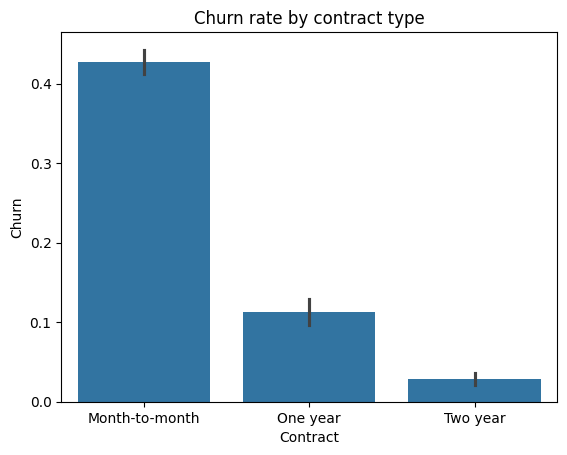

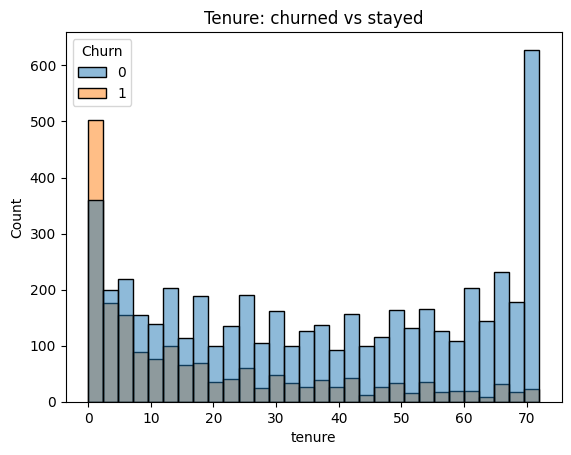

In [ ]:
import matplotlib.pyplot as plt  # for plots
import seaborn as sns            # nicer plots

# 0. Leftover check from before: duplicate rows
print("Duplicates:", df.duplicated().sum())

# 1. Overall churn rate
print("Churn rate:", df["Churn"].mean())  # mean of 0/1 column = percentage who churned

# 2. Churn rate by contract type
print(df.groupby("Contract")["Churn"].mean())

# 3. Average tenure and monthly charges: churned vs stayed
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean())

# 4. Plot: churn rate by contract
sns.barplot(x="Contract", y="Churn", data=df)  # bar height = churn rate
plt.title("Churn rate by contract type")
plt.show()

# 5. Plot: tenure distribution for churned vs stayed
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Tenure: churned vs stayed")
plt.show()

EDA, part 2: churn rate for the other categorical columns
Same groupby idea as before, now with a loop so we don't repeat code:

InternetService
Fiber optic    0.418928
DSL            0.189591
No             0.074050
Name: Churn, dtype: float64

PaymentMethod
Electronic check             0.452854
Mailed check                 0.191067
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Name: Churn, dtype: float64

TechSupport
No                     0.416355
Yes                    0.151663
No internet service    0.074050
Name: Churn, dtype: float64

OnlineSecurity
No                     0.417667
Yes                    0.146112
No internet service    0.074050
Name: Churn, dtype: float64

PaperlessBilling
Yes    0.335651
No     0.163301
Name: Churn, dtype: float64

SeniorCitizen
1    0.416813
0    0.236062
Name: Churn, dtype: float64



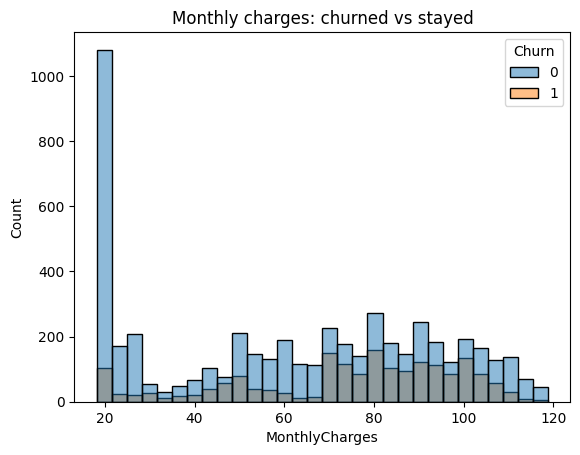

In [ ]:
# Churn rate for several categorical columns
cat_cols = ["InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "PaperlessBilling", "SeniorCitizen"]

for col in cat_cols:                      # repeat for each column in the list
    print(df.groupby(col)["Churn"].mean().sort_values(ascending=False))
    print()                               # blank line between results

# Monthly charges: churned vs stayed
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30)
plt.title("Monthly charges: churned vs stayed")
plt.show()

tenure           -0.352229
TotalCharges     -0.198324
SeniorCitizen     0.150889
MonthlyCharges    0.193356
Churn             1.000000
Name: Churn, dtype: float64


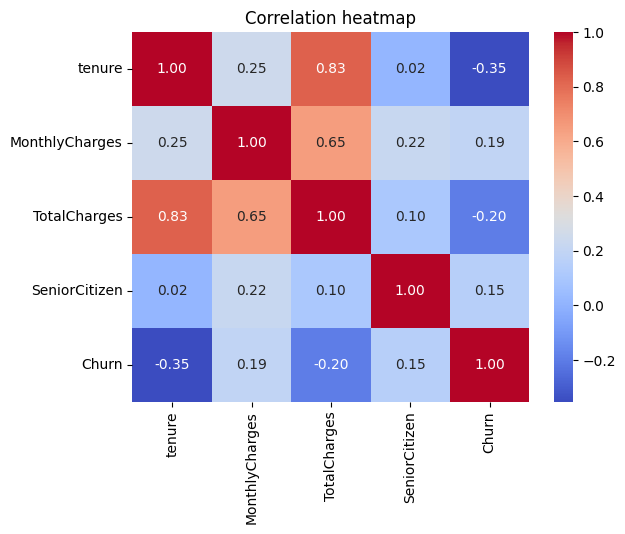

In [ ]:
# Select only the numeric columns
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]

# Correlation = how strongly two columns move together (-1 to +1)
corr = df[num_cols].corr()
print(corr["Churn"].sort_values())  # correlation of each column with Churn

# Heatmap to see all correlations at once
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")  # annot shows the numbers
plt.title("Correlation heatmap")
plt.show()

Run EDA on every categorical column

In [ ]:
# Every text column + SeniorCitizen (a category stored as 0/1)
cat_cols = df.select_dtypes(include="object").columns.tolist() + ["SeniorCitizen"]

for col in cat_cols:
    print(df.groupby(col)["Churn"].mean().round(3))
    print()

gender
Female    0.269
Male      0.262
Name: Churn, dtype: float64

Partner
No     0.330
Yes    0.197
Name: Churn, dtype: float64

Dependents
No     0.313
Yes    0.155
Name: Churn, dtype: float64

PhoneService
No     0.249
Yes    0.267
Name: Churn, dtype: float64

MultipleLines
No                  0.250
No phone service    0.249
Yes                 0.286
Name: Churn, dtype: float64

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64

OnlineSecurity
No                     0.418
No internet service    0.074
Yes                    0.146
Name: Churn, dtype: float64

OnlineBackup
No                     0.399
No internet service    0.074
Yes                    0.215
Name: Churn, dtype: float64

DeviceProtection
No                     0.391
No internet service    0.074
Yes                    0.225
Name: Churn, dtype: float64

TechSupport
No                     0.416
No internet service    0.074
Yes                    0.152
Name: Churn, d

Step 5: train/test split. We do it before encoding or scaling to avoid data leakage

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("Churn", axis=1)  # features: everything except the target
y = df["Churn"]               # target: what we predict

# 80% train, 20% test. stratify=y keeps the same churn % in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())  # churn rate in each part

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]            # to scale
cat_cols = X_train.select_dtypes(include="object").columns.tolist() # to encode

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
], remainder="passthrough")  # SeniorCitizen is already 0/1, so it passes through

# fit_transform on TRAIN: learns the scaling and categories from train only
X_train_p = preprocessor.fit_transform(X_train)
# transform on TEST: applies what was learned, with no re-learning (avoids leakage)
X_test_p = preprocessor.transform(X_test)

print(X_train_p.shape, X_test_p.shape)

(5634, 45) (1409, 45)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model = LogisticRegression(max_iter=1000)  # max_iter gives it enough steps to converge
model.fit(X_train_p, y_train)              # learn from training data

y_pred = model.predict(X_test_p)               # predicted class: 0 or 1
y_prob = model.predict_proba(X_test_p)[:, 1]   # predicted probability of churn

print(classification_report(y_test, y_pred))   # precision, recall, F1
print(confusion_matrix(y_test, y_pred))        # correct and wrong predictions
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

[[926 109]
 [165 209]]
ROC-AUC: 0.8419566509080574


In [ ]:
# class_weight="balanced": کم تعداد والی class (churn) کو زیادہ وزن ملتا ہے
model_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
model_bal.fit(X_train_p, y_train)

y_pred_bal = model_bal.predict(X_test_p)
y_prob_bal = model_bal.predict_proba(X_test_p)[:, 1]

print(classification_report(y_test, y_pred_bal))
print(confusion_matrix(y_test, y_pred_bal))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_bal))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

[[747 288]
 [ 81 293]]
ROC-AUC: 0.8416337285902502


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# مختلف thresholds آزمائیں: probability اس سے زیادہ ہو تو "churn" کہیں
for t in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (y_prob >= t).astype(int)   # 1 اگر probability >= threshold
    print(
        f"threshold={t:.2f} | "
        f"precision={precision_score(y_test, pred):.2f} | "
        f"recall={recall_score(y_test, pred):.2f} | "
        f"f1={f1_score(y_test, pred):.2f}"
    )


threshold=0.25 | precision=0.50 | recall=0.81 | f1=0.62
threshold=0.30 | precision=0.52 | recall=0.75 | f1=0.62
threshold=0.35 | precision=0.54 | recall=0.71 | f1=0.61
threshold=0.40 | precision=0.57 | recall=0.67 | f1=0.61
threshold=0.45 | precision=0.60 | recall=0.61 | f1=0.61
threshold=0.50 | precision=0.66 | recall=0.56 | f1=0.60


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# n_estimators = درختوں کی تعداد، class_weight = churn class کو زیادہ وزن
rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced",
    random_state=42, n_jobs=-1
)
rf.fit(X_train_p, y_train)

rf_prob = rf.predict_proba(X_test_p)[:, 1]   # churn کی probability
rf_pred = (rf_prob >= 0.5).astype(int)       # 0.5 threshold پر فیصلہ

print(classification_report(y_test, rf_pred))
print(confusion_matrix(y_test, rf_pred))
print("RF ROC-AUC:", roc_auc_score(y_test, rf_prob))

              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1035
           1       0.61      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409

[[923 112]
 [197 177]]
RF ROC-AUC: 0.8200844764783383


In [ ]:
from sklearn.metrics import roc_auc_score, precision_recall_curve

# 1. Overfitting check: train اور test کا AUC
print("LR train AUC:", roc_auc_score(y_train, model.predict_proba(X_train_p)[:, 1]))
print("LR test  AUC:", roc_auc_score(y_test, y_prob))
print("RF train AUC:", roc_auc_score(y_train, rf.predict_proba(X_train_p)[:, 1]))
print("RF test  AUC:", roc_auc_score(y_test, rf_prob))

# 2. منصفانہ موازنہ: recall 0.75 پر کس کی precision بہتر ہے
def precision_at_recall(y_true, prob, target=0.75):
    p, r, t = precision_recall_curve(y_true, prob)  # ہر threshold پر precision اور recall
    return p[r >= target].max()                     # جن میں recall >= target ہو، ان میں بہترین precision

print("LR precision at recall 0.75:", precision_at_recall(y_test, y_prob))
print("RF precision at recall 0.75:", precision_at_recall(y_test, rf_prob))

LR train AUC: 0.8493085189336123
LR test  AUC: 0.8419566509080574
RF train AUC: 0.9998502700068927
RF test  AUC: 0.8200844764783383
LR precision at recall 0.75: 0.5262172284644194
RF precision at recall 0.75: 0.504424778761062


In [ ]:
import pandas as pd

check = pd.DataFrame({
    "probability": y_prob[:5].round(2),            # model کی probability
    "flag_at_0.50": (y_prob[:5] >= 0.50).astype(int),
    "flag_at_0.30": (y_prob[:5] >= 0.30).astype(int),
    "actual_churn": y_test.values[:5],             # اصل حقیقت
})
print(check)

   probability  flag_at_0.50  flag_at_0.30  actual_churn
0         0.05             0             0             0
1         0.68             1             1             0
2         0.06             0             0             0
3         0.40             0             1             0
4         0.02             0             0             0


In [ ]:
import numpy as np

top_n = 100                                  # ٹیم کی صلاحیت
order = np.argsort(y_prob)[::-1]             # سب سے زیادہ probability والے پہلے
top_idx = order[:top_n]                      # اوپر کے 100 کسٹمرز

threshold = y_prob[top_idx[-1]]              # 100ویں کسٹمر کی probability
caught = y_test.values[top_idx].sum()        # ان 100 میں اصل churners کتنے تھے

print("Threshold:", round(threshold, 2))
print("Precision:", caught / top_n)
print("Recall:", caught / y_test.sum())

Threshold: 0.69
Precision: 0.73
Recall: 0.19518716577540107


In [ ]:
# max_depth: درخت کی گہرائی محدود
# min_samples_leaf: ہر آخری شاخ میں کم از کم 20 کسٹمرز ہوں، تاکہ ایک کسٹمر کو رٹا نہ جا سکے
rf2 = RandomForestClassifier(
    n_estimators=300, max_depth=6, min_samples_leaf=20,
    class_weight="balanced", random_state=42, n_jobs=-1
)
rf2.fit(X_train_p, y_train)

print("RF2 train AUC:", roc_auc_score(y_train, rf2.predict_proba(X_train_p)[:, 1]))
print("RF2 test  AUC:", roc_auc_score(y_test, rf2.predict_proba(X_test_p)[:, 1]))

RF2 train AUC: 0.8644997701123419
RF2 test  AUC: 0.8422989485649333


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest (depth 6)": RandomForestClassifier(
        n_estimators=300, max_depth=6, min_samples_leaf=20,
        random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=200, random_state=42),
}

for name, m in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)])  # raw X_train دیں، X_train_p نہیں
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name}: AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: AUC = 0.846 (+/- 0.013)
Random Forest (depth 6): AUC = 0.847 (+/- 0.010)
Gradient Boosting: AUC = 0.848 (+/- 0.012)


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

final_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

# Each training row is predicted by a model that never saw that row
cv_prob = cross_val_predict(
    final_pipe, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (cv_prob >= t).astype(int)
    print(f"threshold={t:.2f} | precision={precision_score(y_train, pred):.2f} "
          f"| recall={recall_score(y_train, pred):.2f} | f1={f1_score(y_train, pred):.2f}")

threshold=0.20 | precision=0.48 | recall=0.85 | f1=0.61
threshold=0.25 | precision=0.51 | recall=0.82 | f1=0.63
threshold=0.30 | precision=0.54 | recall=0.77 | f1=0.63
threshold=0.35 | precision=0.57 | recall=0.72 | f1=0.64
threshold=0.40 | precision=0.59 | recall=0.66 | f1=0.63
threshold=0.45 | precision=0.62 | recall=0.60 | f1=0.61
threshold=0.50 | precision=0.65 | recall=0.54 | f1=0.59


In [ ]:
from sklearn.metrics import confusion_matrix

cost_discount = 1   # cost of calling/discounting one customer
cost_lost = 5       # loss when one real churner leaves

for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (cv_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    # false alarms cost a discount, missed churners cost a lost customer
    total_cost = fp * cost_discount + fn * cost_lost
    print(f"threshold={t:.2f} | false alarms={fp} | missed={fn} | total cost={total_cost}")

threshold=0.20 | false alarms=1411 | missed=218 | total cost=2501
threshold=0.25 | false alarms=1175 | missed=273 | total cost=2540
threshold=0.30 | false alarms=971 | missed=349 | total cost=2716
threshold=0.35 | false alarms=809 | missed=423 | total cost=2924
threshold=0.40 | false alarms=680 | missed=502 | total cost=3190
threshold=0.45 | false alarms=543 | missed=596 | total cost=3523
threshold=0.50 | false alarms=431 | missed=682 | total cost=3841


In [ ]:
for t in [0.10, 0.15, 0.20, 0.25, 0.30]:
    pred = (cv_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    total_cost = fp * cost_discount + fn * cost_lost
    print(f"threshold={t:.2f} | false alarms={fp} | missed={fn} | total cost={total_cost}")

threshold=0.10 | false alarms=2108 | missed=87 | total cost=2543
threshold=0.15 | false alarms=1751 | missed=130 | total cost=2401
threshold=0.20 | false alarms=1411 | missed=218 | total cost=2501
threshold=0.25 | false alarms=1175 | missed=273 | total cost=2540
threshold=0.30 | false alarms=971 | missed=349 | total cost=2716


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

final_pipe.fit(X_train, y_train)                        # train on training data only
test_prob = final_pipe.predict_proba(X_test)[:, 1]      # churn probability for test customers
test_pred = (test_prob >= 0.15).astype(int)             # our chosen threshold

print(classification_report(y_test, test_pred))
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
print("False alarms:", fp, "| Missed:", fn)
print("Total cost:", fp * 1 + fn * 5)
print("Cost if we call nobody:", y_test.sum() * 5)
print("Cost if we call everybody:", (y_test == 0).sum() * 1)

              precision    recall  f1-score   support

           0       0.95      0.58      0.72      1035
           1       0.44      0.91      0.59       374

    accuracy                           0.67      1409
   macro avg       0.69      0.75      0.66      1409
weighted avg       0.81      0.67      0.69      1409

False alarms: 436 | Missed: 32
Total cost: 596
Cost if we call nobody: 1870
Cost if we call everybody: 1035


In [ ]:
import pandas as pd

names = final_pipe.named_steps["prep"].get_feature_names_out()  # column names after encoding
coefs = final_pipe.named_steps["model"].coef_[0]                # one number per column

coef_table = pd.Series(coefs, index=names).sort_values()
print("Reduce churn the most:")
print(coef_table.head(8))
print("\nIncrease churn the most:")
print(coef_table.tail(8))

Reduce churn the most:
num__tenure                                 -1.249501
cat__Contract_Two year                      -0.770715
cat__InternetService_DSL                    -0.660859
num__MonthlyCharges                         -0.620723
cat__PaperlessBilling_No                    -0.343703
cat__OnlineBackup_No internet service       -0.306057
cat__DeviceProtection_No internet service   -0.306057
cat__TechSupport_No internet service        -0.306057
dtype: float64

Increase churn the most:
remainder__SeniorCitizen               0.144545
cat__OnlineSecurity_No                 0.156808
cat__PaymentMethod_Electronic check    0.197795
cat__StreamingMovies_Yes               0.208304
cat__StreamingTV_Yes                   0.208361
num__TotalCharges                      0.525363
cat__Contract_Month-to-month           0.576117
cat__InternetService_Fiber optic       0.651066
dtype: float64


In [ ]:
import joblib

# Save the full pipeline (preprocessing + model) and our chosen threshold
joblib.dump({"pipeline": final_pipe, "threshold": 0.15}, "churn_model.joblib")

# Test: load it back and score 5 customers
saved = joblib.load("churn_model.joblib")
probs = saved["pipeline"].predict_proba(X_test.head(5))[:, 1]
print(probs.round(2))
print((probs >= saved["threshold"]).astype(int))

[0.05 0.68 0.06 0.4  0.02]
[0 1 0 1 0]


In [ ]:
from google.colab import files
files.download("churn_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

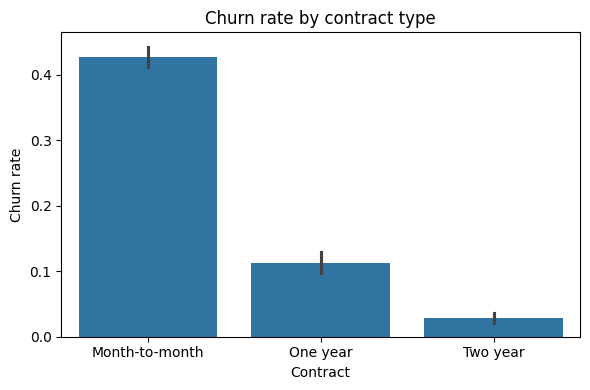

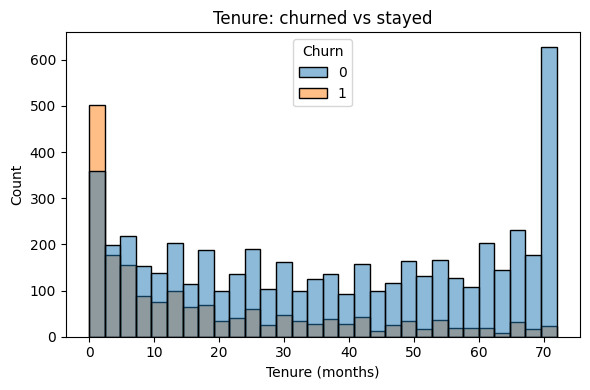

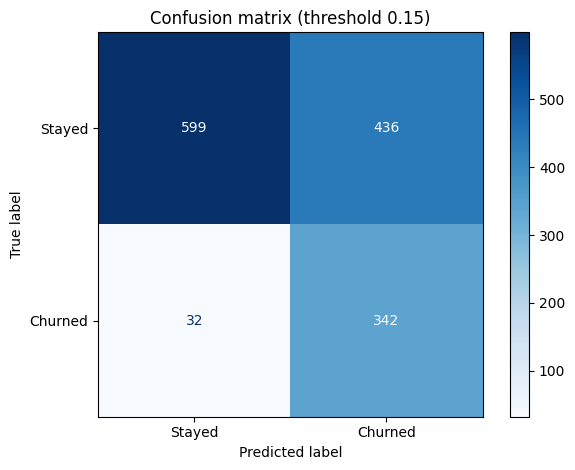

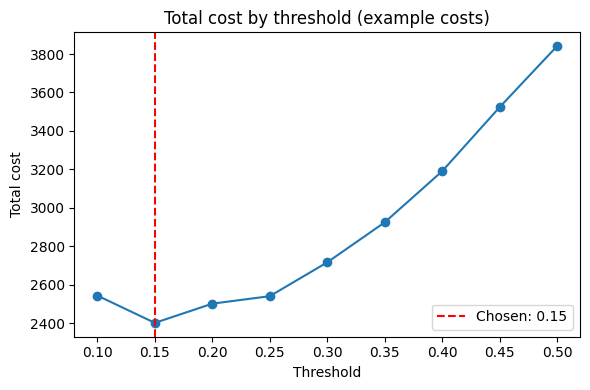

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

os.makedirs("images", exist_ok=True)

# 1. Churn rate by contract
plt.figure(figsize=(6, 4))
sns.barplot(x="Contract", y="Churn", data=df)
plt.title("Churn rate by contract type")
plt.ylabel("Churn rate")
plt.tight_layout()
plt.savefig("images/churn_by_contract.png", dpi=150)
plt.show()

# 2. Tenure: churned vs stayed (0 = stayed, 1 = churned)
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Tenure: churned vs stayed")
plt.xlabel("Tenure (months)")
plt.tight_layout()
plt.savefig("images/tenure_vs_churn.png", dpi=150)
plt.show()

# 3. Confusion matrix on the test set at threshold 0.15
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Stayed", "Churned"], cmap="Blues"
)
plt.title("Confusion matrix (threshold 0.15)")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=150)
plt.show()

# 4. Total cost at each threshold (example costs: 1 and 5)
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
costs = []
for t in thresholds:
    pred = (cv_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    costs.append(fp * 1 + fn * 5)   # false alarm = 1, missed churner = 5

plt.figure(figsize=(6, 4))
plt.plot(thresholds, costs, marker="o")
plt.axvline(0.15, color="red", linestyle="--", label="Chosen: 0.15")
plt.title("Total cost by threshold (example costs)")
plt.xlabel("Threshold")
plt.ylabel("Total cost")
plt.legend()
plt.tight_layout()
plt.savefig("images/cost_vs_threshold.png", dpi=150)
plt.show()

In [ ]:
!zip -r images.zip images
from google.colab import files
files.download("images.zip")

  adding: images/ (stored 0%)
  adding: images/confusion_matrix.png (deflated 16%)
  adding: images/tenure_vs_churn.png (deflated 18%)
  adding: images/churn_by_contract.png (deflated 21%)
  adding: images/cost_vs_threshold.png (deflated 10%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn, pandas
print("scikit-learn==" + sklearn.__version__)
print("pandas==" + pandas.__version__)

scikit-learn==1.6.1
pandas==2.2.3
